# Global Daily SST (OSTIA) Analysis: Identifying Marine Extremes with `MarEx-Detect`

This notebook turns 40 years (1982-2022) of daily OSTIA sea-surface temperature, regridded to 0.25° (720 × 1440 cells), into a boolean record of marine heatwaves with two combinations of anomaly and threshold method:

| | Anomaly | Threshold |
|---|---|---|
| Part 1 | `shifting_baseline`: anomaly from a smoothed day-of-year climatology of the preceding `window_years` (15) | `seasonal_percentile`: day-of-year 95th percentile, after Hobday et al. (2016) |
| Part 2 | `detrend_harmonic`: removes the mean, the annual & semi-annual harmonics, and a linear + quadratic trend | `global_percentile`: one 95th percentile per cell over all days |

Part 3 compares the two. The shifting baseline consumes its first `window_years` as spin-up, so Part 1's record starts
15 years after the input does. Part 1's output feeds the tracking example, `02_id_track_events.ipynb`.

Everything runs on a single node with 64 cores and 128 GB. Each stage prints its wall time and peak memory as it
finishes, and the table at the end collects them. The other two anomaly methods (`fixed_baseline` and
`detrend_fixed_baseline`) and the trade-offs between all four are described under
[Choosing an Anomaly Method](https://marex.readthedocs.io/en/latest/guide/anomalies.html#choosing-a-method).

In [1]:
from getpass import getuser
from pathlib import Path

import dask
import numpy as np
import xarray as xr

import marEx
import marEx.helper as hpc

2026-10-10 21:39:49 - marEx - INFO - [PID:419237] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
sst_store = scratch_dir / "mhws" / "ostia.zarr"  # daily OSTIA SST on a 0.25° grid, 1982-01-01 to 2022-05-31
out_dir = scratch_dir / "marEx" / "examples" / "gridded"

period = slice("1982-01-01", "2022-05-31")  # 40 years of input
window_years = 15  # shifting-baseline length in years. Part 1's output starts this many years after `period`
plot_window = slice("2016-01-01", "2021-12-31")  # x-range of the time-series figures

# One node: 4 workers x 16 threads x 28 GB = 64 cores, 112 GB for the workers, the rest of 128 GB for the client
n_workers, threads_per_worker, memory_limit = 4, 16, "28GB"

In [3]:
out_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is passed explicitly because on an HPC node Dask sizes workers from the whole node's memory,
# not from the job's allocation, and without it the workers can claim more than the job was granted.
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-10 21:40:02 - marEx.helper.cluster - INFO - [PID:419237] - Starting local Dask cluster with 4 workers, 16 threads each


2026-10-10 21:40:02 - marEx.helper.dask_config - INFO - [PID:419237] - Configuring Dask for HPC environment


2026-10-10 21:40:02 - marEx.helper.dask_config - INFO - [PID:419237] - Dask temporary directory: /scratch/b/b382615/marEx/dask/tmp304j3pn3


2026-10-10 21:40:02 - marEx.helper.dask_config - INFO - [PID:419237] - Dask configuration completed


2026-10-10 21:40:02 - marEx.helper.cluster - INFO - [PID:419237] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


...

2026-10-10 21:40:02 - marEx.helper.cluster - INFO - [PID:419237] - Starting Local cluster startup


2026-10-10 21:40:04 - marEx.helper.cluster - INFO - [PID:419237] - Completed Local cluster startup in 2.20s


Hostname: l40019
Forward Port: l40019:8787
Dashboard Link: localhost:8787/status
2026-10-10 21:40:04 - marEx.helper.cluster - INFO - [PID:419237] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-10-10 21:40:04 - marEx.helper.cluster - INFO - [PID:419237] - After cluster startup - Memory Usage - RSS: 571.7MB, Virtual: 24698.9MB, Percent: 0.2%, Available: 240947.6MB


2026-10-10 21:40:04 - marEx.helper.resources - INFO - [PID:419237] - Cluster: 4 workers, 64 threads, memory_limit per worker [28.0] GB (112 GB total)


## Pre-Process with Shifting-Baseline & Hobday et al. (2016) Definition for Extremes

### A note on chunking

Both methods read the input with one chunking: a small time chunk and the whole domain in each chunk
(`{"time": 30, "lat": -1, "lon": -1}`). The climatology and percentile reductions are global in time, so a task's
memory is `n_time × (cells in one spatial chunk) × 4 B`, and marEx tiles the spatial dimension internally wherever a
reduction needs it. A large time chunk would only inflate each input chunk to several GB. The sizing rules are under
[Memory Management and Chunking](https://marex.readthedocs.io/en/latest/guide/performance.html#chunking).

In [4]:
sst = xr.open_zarr(sst_store, chunks={"time": 30, "lat": -1, "lon": -1}).sst.sel(time=period)
sst

<xarray.DataArray 'sst' (time: 14761, lat: 720, lon: 1440)> Size: 61GB
dask.array<open_dataset-sst, shape=(14761, 720, 1440), dtype=float32, chunksize=(30, 720, 1440), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
  * time     (time) datetime64[ns] 118kB 1982-01-01T12:00:00 ... 2022-05-31T1...
Attributes:
    comment:         OSTIA foundation SST
    long_name:      analysed sea surface temperature
    reference:      C.J. Donlon, M. Martin,J.D. Stark, J. Roberts-Jones, E. F...
    source:         AMSR2-REMSS-L2P-v2.0, AMSRE-REMSS-L2P-v2.0, TMI-REMSS-L2P...
    standard_name:  sea_surface_foundation_temperature
    units:          kelvin
    valid_max:      4500
    valid_min:      -300

In [5]:
with monitor.stage("Detect: shifting baseline + Hobday"):
    extremes_ds = marEx.preprocess_data(
        sst,
        method_anomaly="shifting_baseline",  # anomaly from a backward-looking climatology of the previous `window_years`
        method_extreme="seasonal_percentile",  # day-of-year threshold (Hobday et al., 2016)
        threshold_percentile=95,
        window_years=window_years,
        smooth_days=21,  # smoothing applied to the climatology (days)
        window_days=11,  # samples from an 11-day window around each day of year enter its percentile
        dimensions={"time": "time", "x": "lon", "y": "lat"},  # a "y" dimension tells marEx this is a lat/lon grid
        dask_chunks={"time": 25},  # chunking of the output
    )
    extremes_ds.to_zarr(out_dir / "extremes_shifting_hobday.zarr", mode="w")
extremes_ds

2026-10-10 21:40:45 - marEx.pipeline - INFO - [PID:419237] - Starting data preprocessing - Method: shifting_baseline -> seasonal_percentile


2026-10-10 21:40:45 - marEx.pipeline - INFO - [PID:419237] - Parameters: percentile=95%, method_percentile=approximate


2026-10-10 21:40:45 - marEx.anomaly.api - INFO - [PID:419237] - Computing anomalies - method: shifting_baseline


2026-10-10 21:40:52 - marEx.anomaly.api - INFO - [PID:419237] - Starting Anomaly computation using shifting_baseline method


2026-10-10 21:40:58 - marEx.anomaly.api - INFO - [PID:419237] - Completed Anomaly computation using shifting_baseline method in 6.20s


...

2026-10-10 22:46:51 - marEx.core.finalise - INFO - [PID:419237] - Starting Dataset persistence and optimisation


2026-10-10 22:46:51 - marEx.core.finalise - INFO - [PID:419237] - Completed Dataset persistence and optimisation in 0.03s


2026-10-10 22:55:21 - marEx.extremes.api - INFO - [PID:419237] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(286116865) extreme events identified


Detect: shifting baseline + Hobday: 75.2 min, peak worker memory 53.0 GB of 112 GB, client 3.1 GB, spilled 73.0 GB, restarts 0


<xarray.Dataset> Size: 50GB
Dimensions:         (lat: 720, lon: 1440, time: 9282, dayofyear: 366)
Coordinates:
  * lat             (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time            (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-0...
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
Data variables:
    dat_anomaly     (time, lat, lon) float32 38GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 10GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    thresholds      (lat, lon, dayofyear) float32 2GB dask.array<chunksize=(720, 1440, 25), meta=np.ndarray>
Attributes:
    method_anomaly:        shifting_baseline
    preprocessing_steps:   ['Rolling climatology using 15 years', 'Smoothed w...
    window_years:          15
    smooth_days:           21
    method_extreme:        seasonal_percentile
    threshold_percentile:  95
    tail:                  upper
    window_days:           11
    window_spatial:        5
    method_percentile:     approximate
    precision:             0.014025858561197917
    max_anomaly:           21.038787841796875

## Pre-Process with Detrend Harmonic Baseline & Global-in-Time Threshold Value

The same input, so the `sst` loaded above is reused.

In [6]:
with monitor.stage("Detect: harmonic detrend + global threshold"):
    extremes_ds = marEx.preprocess_data(
        sst,
        method_anomaly="detrend_harmonic",  # removes the mean, annual & semi-annual harmonics and the trend
        method_extreme="global_percentile",  # one threshold per cell, over all days
        threshold_percentile=95,
        detrend_orders=[1, 2],  # linear + quadratic trend
        dimensions={"time": "time", "x": "lon", "y": "lat"},
        dask_chunks={"time": 25},
    )
    extremes_ds.to_zarr(out_dir / "extremes_harmonic_global.zarr", mode="w")
extremes_ds

2026-10-10 22:55:55 - marEx.pipeline - INFO - [PID:419237] - Starting data preprocessing - Method: detrend_harmonic -> global_percentile


2026-10-10 22:55:55 - marEx.pipeline - INFO - [PID:419237] - Parameters: percentile=95%, method_percentile=approximate


2026-10-10 22:55:55 - marEx.anomaly.api - INFO - [PID:419237] - Computing anomalies - method: detrend_harmonic


2026-10-10 22:56:02 - marEx.anomaly.api - INFO - [PID:419237] - Starting Anomaly computation using detrend_harmonic method


2026-10-10 22:56:03 - marEx.anomaly.api - INFO - [PID:419237] - Completed Anomaly computation using detrend_harmonic method in 1.50s


...

2026-10-10 23:16:14 - marEx.core.finalise - INFO - [PID:419237] - Completed Dataset persistence and optimisation in 0.07s


/scratch/b/b382615/marEx/marex_snap/R43/marEx/extremes/histogram.py:1247: UserWarning: Quantile values below expected range in some locations: min=-0.0006 < 0.0122. This is likely due to a constant anomaly in certain (e.g. due to sea ice). Double check the computed threshold values are correct.
  threshold = _apply_threshold_bounds(


2026-10-10 23:18:13 - marEx.extremes.api - INFO - [PID:419237] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(482984267) extreme events identified


Detect: harmonic detrend + global threshold: 23.2 min, peak worker memory 54.5 GB of 112 GB, client 3.2 GB, spilled 65.1 GB, restarts 0


<xarray.Dataset> Size: 77GB
Dimensions:         (lat: 720, lon: 1440, time: 14761)
Coordinates:
  * lat             (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time            (time) datetime64[ns] 118kB 1982-01-01T12:00:00 ... 2022-...
Data variables:
    dat_anomaly     (time, lat, lon) float32 61GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 15GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    thresholds      (lat, lon) float64 8MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
Attributes:
    method_anomaly:        detrend_harmonic
    preprocessing_steps:   ['Removed polynomial trend orders=[1, 2] & seasona...
    detrend_orders:        [1, 2]
    force_zero_mean:       1
    standardise:           0
    method_extreme:        global_percentile
    threshold_percentile:  95
    tail:                  upper
    method_percentile:     approximate
    precision:             0.012176350911458333
    max_anomaly:           18.2645263671875

# Compare Results of Pre-Processing Methods

In [7]:
import calendar

import dask.array as da
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

In [8]:
extremes_ds_shifting = xr.open_zarr(out_dir / "extremes_shifting_hobday.zarr", chunks={})

# Compare over the shifting-baseline record, which starts `window_years` after the input
time_slice = slice(extremes_ds_shifting.time.values[0], extremes_ds_shifting.time.values[-1])
sst = xr.open_zarr(sst_store, chunks={}).sst.sel(time=time_slice).chunk({"time": 75, "lat": "auto", "lon": "auto"})

extremes_ds_shifting = extremes_ds_shifting.sel(time=time_slice).chunk({"time": 75, "lat": "auto", "lon": "auto"})
extremes_ds_detrend = (
    xr.open_zarr(out_dir / "extremes_harmonic_global.zarr", chunks={})
    .sel(time=time_slice)
    .chunk({"time": 75, "lat": "auto", "lon": "auto"})
)

## Example of Timeseries and Thresholds

A single threshold for every day of the year (`Harmonic+Global`) flags spurious extremes whenever the seasonal cycle
shifts systematically, for example when the seasonal transition arrives a little earlier or later than usual. The
day-of-year threshold (`Shifting+Hobday`) follows the season.

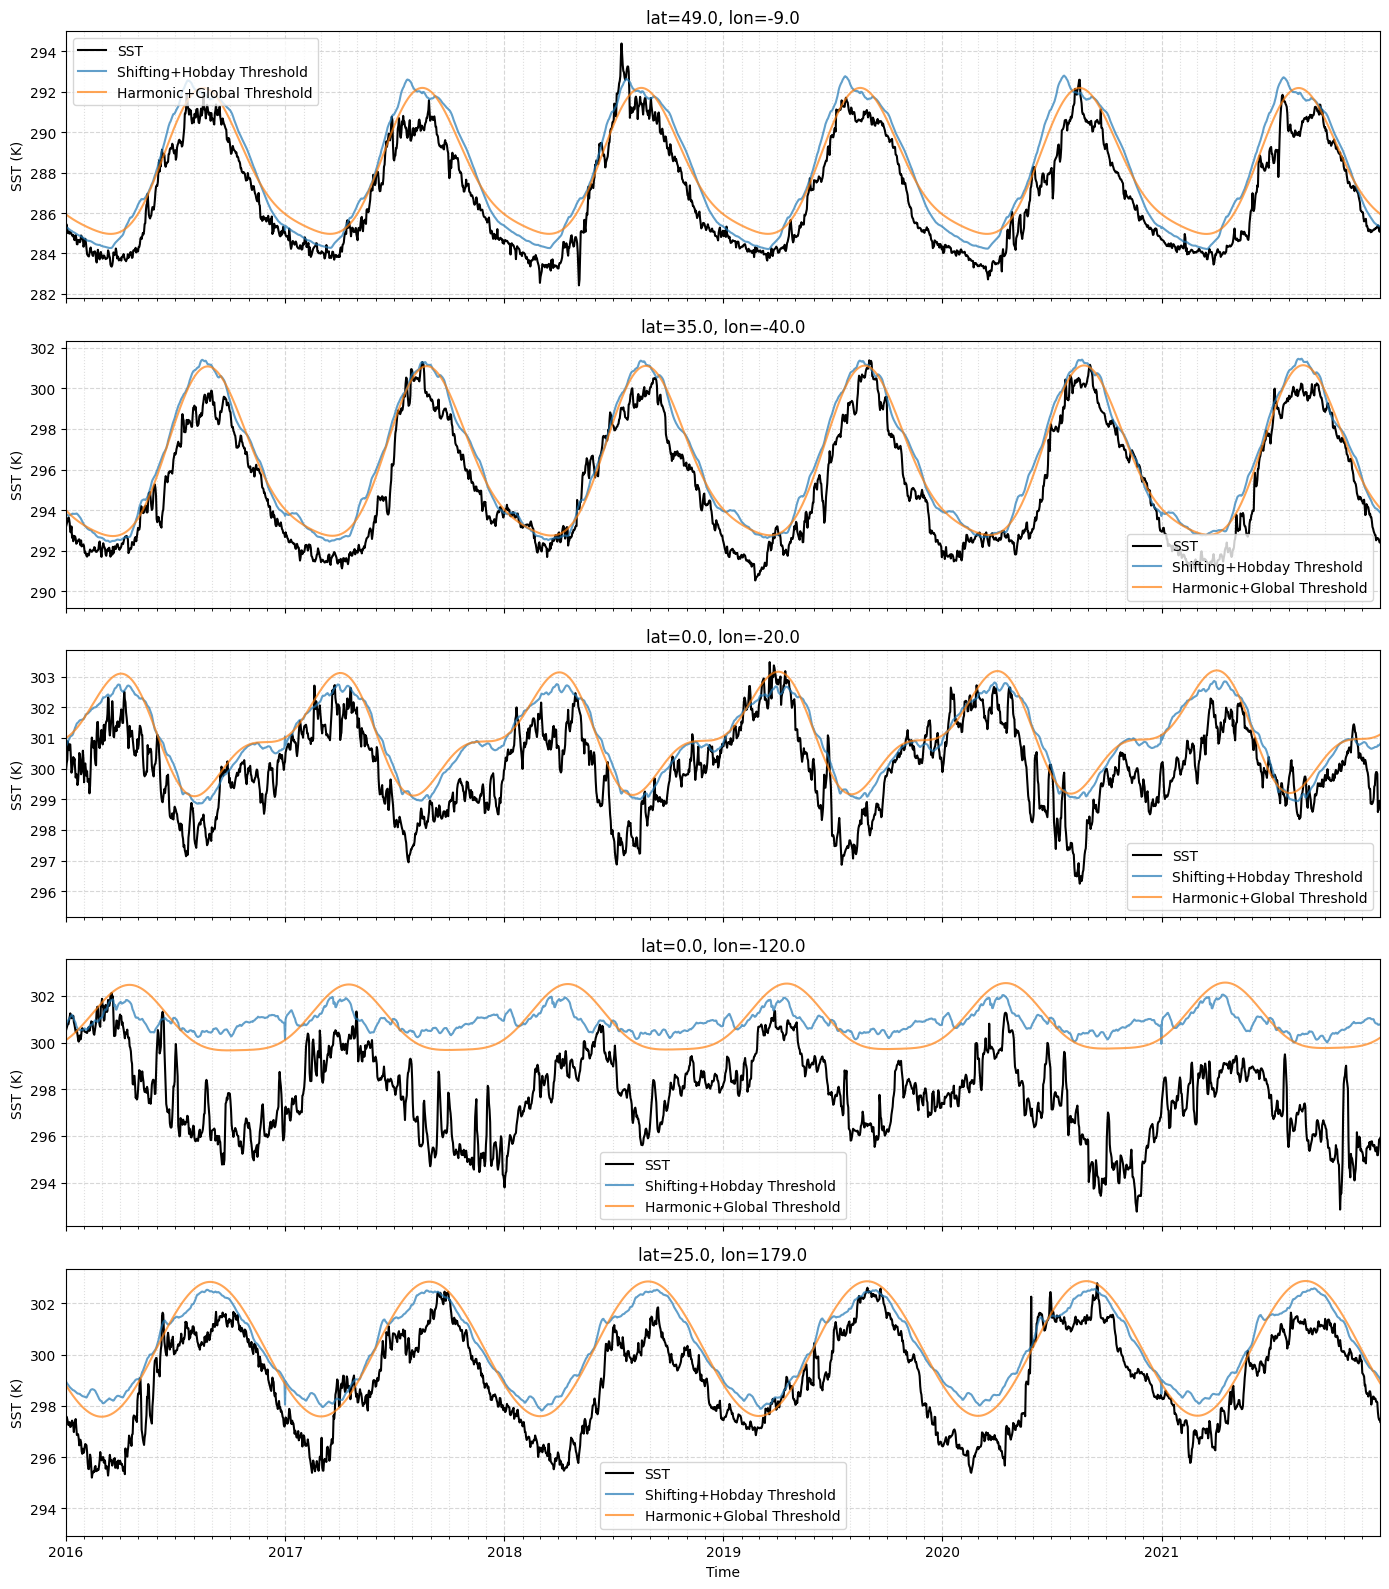

In [9]:
points = [
    (49.0, 351.0 - 360.0),
    (35.0, 320.0 - 360.0),
    (0.0, 340.0 - 360.0),
    (0.0, 240.0 - 360.0),
    (25.0, 179.0),
]

fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

for i, (lat_pt, lon_pt) in enumerate(points):
    sst_pt = sst.sel(lat=lat_pt, lon=lon_pt, method="nearest")
    shifting_thr_pt = (
        sst - extremes_ds_shifting.dat_anomaly + extremes_ds_shifting.thresholds.sel(dayofyear=sst.time.dt.dayofyear)
    ).sel(lat=lat_pt, lon=lon_pt, method="nearest")
    detrend_thr_pt = (sst - extremes_ds_detrend.dat_anomaly + extremes_ds_detrend.thresholds).sel(
        lat=lat_pt, lon=lon_pt, method="nearest"
    )

    axes[i].plot(sst_pt.time, sst_pt, color="black", label="SST")
    axes[i].plot(
        sst_pt.time,
        shifting_thr_pt,
        color="tab:blue",
        label="Shifting+Hobday Threshold",
        alpha=0.7,
    )
    axes[i].plot(
        sst_pt.time,
        detrend_thr_pt,
        color="tab:orange",
        label="Harmonic+Global Threshold",
        alpha=0.7,
    )
    axes[i].set_xlim(np.datetime64(plot_window.start), np.datetime64(plot_window.stop))
    axes[i].set_ylabel("SST (K)")
    axes[i].grid(True, which="major", linestyle="--", alpha=0.5)
    axes[i].grid(True, which="minor", linestyle=":", alpha=0.4, axis="x")
    axes[i].set_title(f"lat={lat_pt}, lon={lon_pt}")
    axes[i].legend()
    axes[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(2, 13)))
    axes[i].legend()


axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

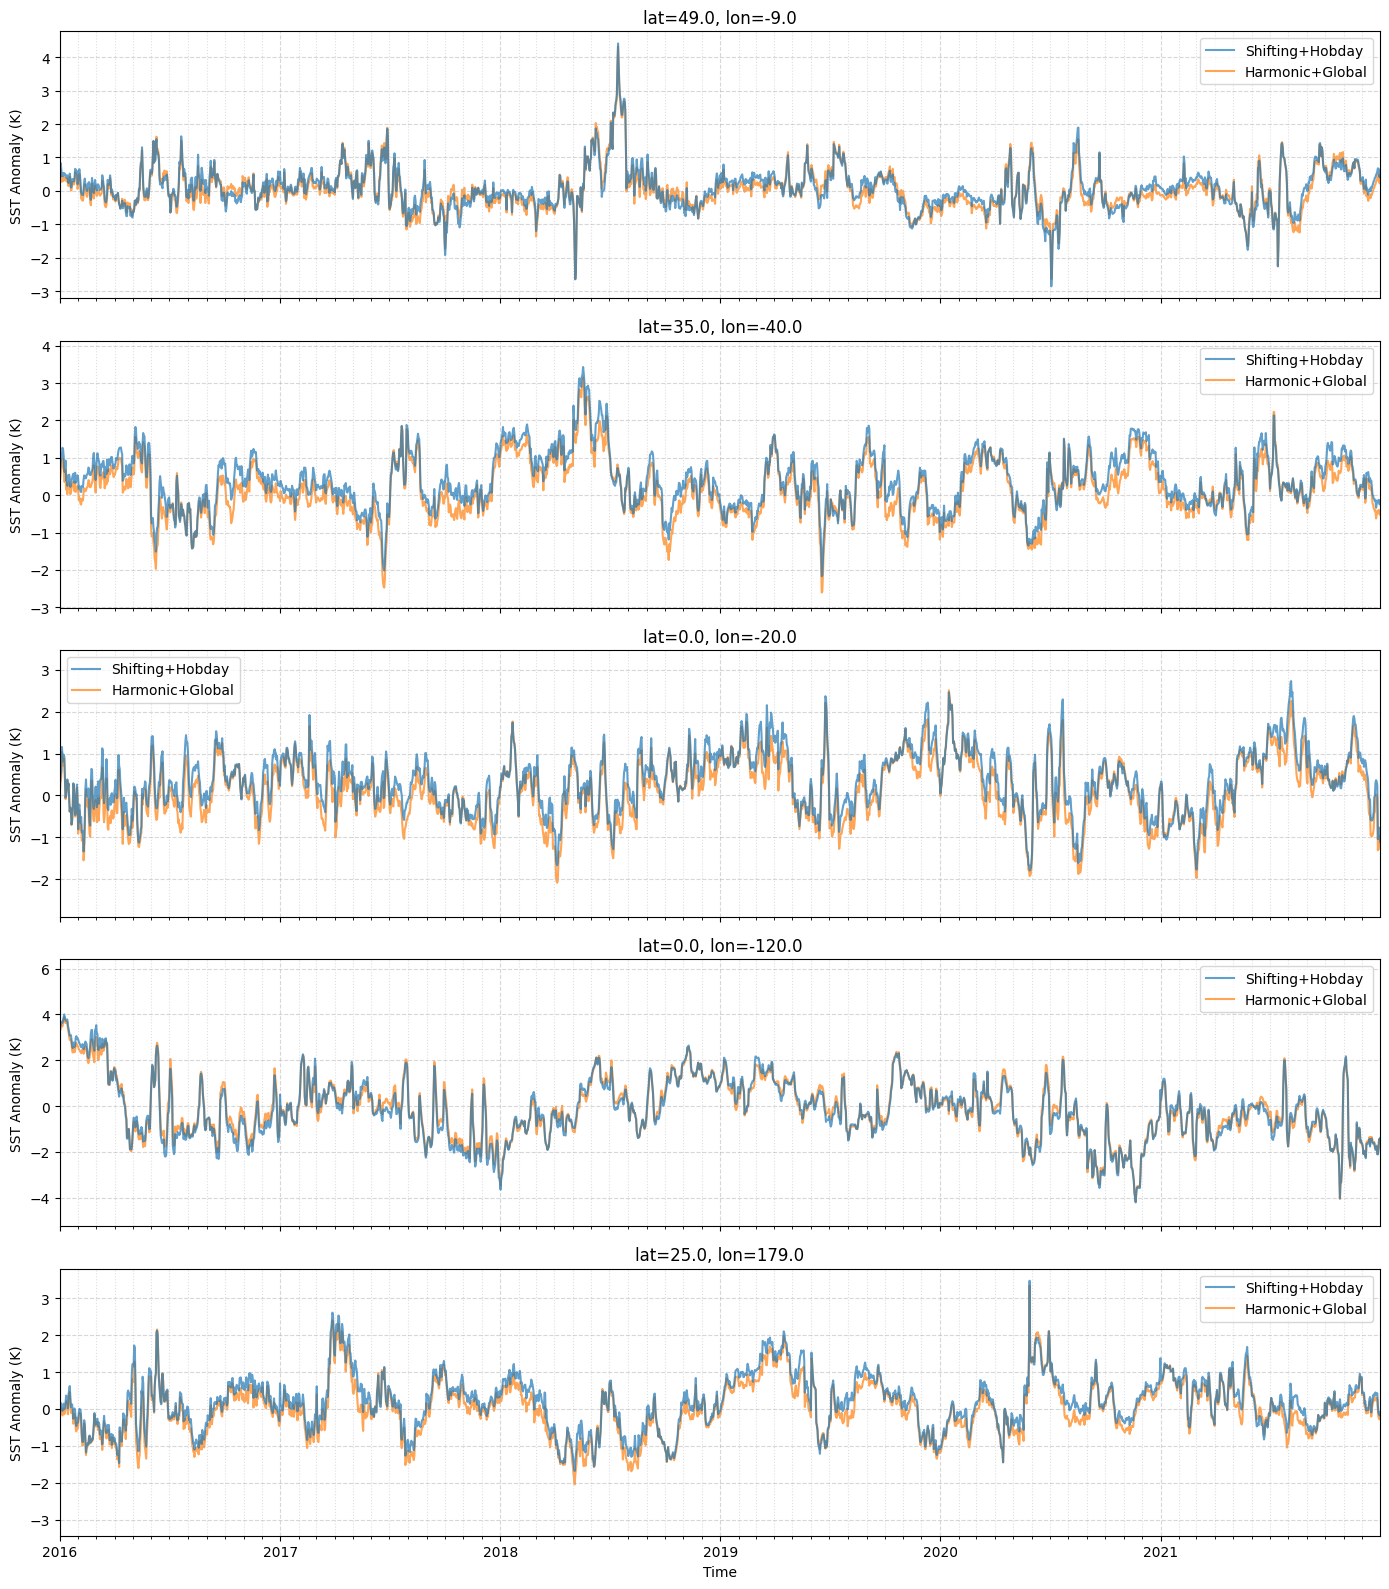

In [10]:
points = [
    (49.0, 351.0 - 360.0),
    (35.0, 320.0 - 360.0),
    (0.0, 340.0 - 360.0),
    (0.0, 240.0 - 360.0),
    (25.0, 179.0),
]

fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

for i, (lat_pt, lon_pt) in enumerate(points):
    sst_pt = sst.sel(lat=lat_pt, lon=lon_pt, method="nearest")
    shifting_anomaly_pt = extremes_ds_shifting.dat_anomaly.sel(lat=lat_pt, lon=lon_pt, method="nearest")
    detrend_anomaly_pt = extremes_ds_detrend.dat_anomaly.sel(lat=lat_pt, lon=lon_pt, method="nearest")

    axes[i].plot(
        shifting_anomaly_pt.time,
        shifting_anomaly_pt,
        color="tab:blue",
        label="Shifting+Hobday",
        alpha=0.7,
        zorder=2,
    )
    axes[i].plot(
        detrend_anomaly_pt.time,
        detrend_anomaly_pt,
        color="tab:orange",
        label="Harmonic+Global",
        alpha=0.7,
        zorder=1,
    )
    axes[i].set_xlim(np.datetime64(plot_window.start), np.datetime64(plot_window.stop))
    axes[i].set_ylabel("SST Anomaly (K)")
    axes[i].grid(True, which="major", linestyle="--", alpha=0.5)
    axes[i].grid(True, which="minor", linestyle=":", alpha=0.4, axis="x")
    axes[i].set_title(f"lat={lat_pt}, lon={lon_pt}")
    axes[i].legend()
    axes[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(2, 13)))

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

## Anomaly Distributions and Variance

The positive shift of the shifting-baseline anomalies comes from the backward-looking climatology. It is intended: the
baseline is the recent past that an adapting organism has experienced.

The harmonic fit (the mean plus annual & semi-annual harmonics) cannot represent the shape of the seasonal cycle
everywhere. Combined with one threshold per cell (`global_percentile`), this produces unphysical seasonal biases in the
variance, although the total variability of the two methods is similar.

/tmp/ipykernel_419237/2714115885.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


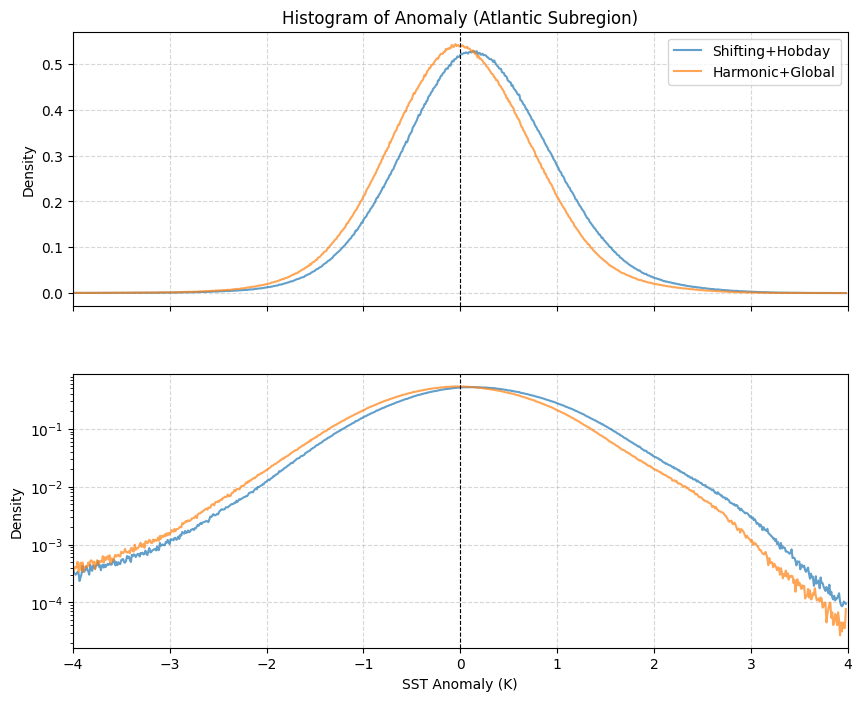

In [11]:
bins = np.arange(-4, 4, 0.01)
lat_slice = slice(35, 40)
lon_slice = slice(-50, -20)

dat_shifting = extremes_ds_shifting.dat_anomaly.sel(lat=lat_slice, lon=lon_slice).data
dat_anomaly = extremes_ds_detrend.dat_anomaly.sel(lat=lat_slice, lon=lon_slice).data

hist_shifting, _ = da.histogram(dat_shifting, bins=bins, density=True)
hist_detrend, _ = da.histogram(dat_anomaly, bins=bins, density=True)

hist_shifting_computed, hist_detrend_computed = dask.compute(hist_shifting, hist_detrend)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"hspace": 0.25})

axes[0].plot(bins[:-1], hist_shifting_computed, label="Shifting+Hobday", alpha=0.7)
axes[0].plot(bins[:-1], hist_detrend_computed, label="Harmonic+Global", alpha=0.7)
axes[0].set_ylabel("Density")
axes[0].set_title("Histogram of Anomaly (Atlantic Subregion)")
axes[0].set_xlim(-4, 4)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].legend()

axes[1].plot(bins[:-1], hist_shifting_computed, label="Shifting+Hobday", alpha=0.7)
axes[1].plot(bins[:-1], hist_detrend_computed, label="Harmonic+Global", alpha=0.7)
axes[1].set_xlabel("SST Anomaly (K)")
axes[1].set_ylabel("Density")
axes[1].set_xlim(-4, 4)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].set_yscale("log")
axes[1].axvline(0, color="black", linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()

/home/b/b382615/opt/anaconda3/envs/super/lib/python3.10/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/b/b382615/opt/anaconda3/envs/super/lib/python3.10/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


/home/b/b382615/opt/anaconda3/envs/super/lib/python3.10/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


/home/b/b382615/opt/anaconda3/envs/super/lib/python3.10/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


2026-10-10 23:23:06 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:23:34 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 28.03s


2026-10-10 23:23:34 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:24:03 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 29.21s


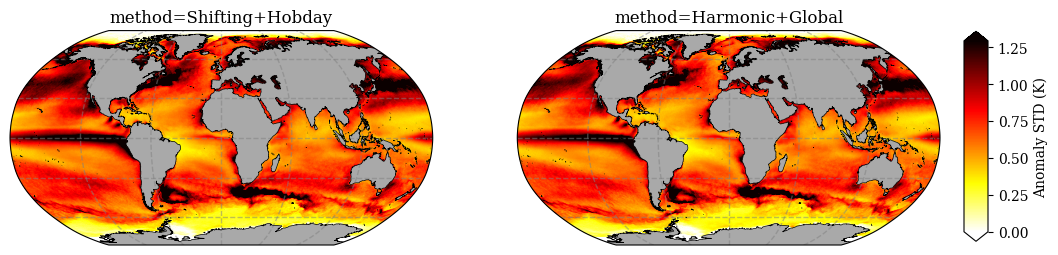

In [12]:
shifting_variance = extremes_ds_shifting.dat_anomaly.std(dim="time")
detrend_variance = extremes_ds_detrend.dat_anomaly.std(dim="time")

config = marEx.PlotConfig(var_units="Anomaly STD (K)", cmap="hot_r", cperc=[0, 96], grid_labels=True)

combined_variance = xr.concat([shifting_variance, detrend_variance], dim="method")
combined_variance = combined_variance.assign_coords(method=["Shifting+Hobday", "Harmonic+Global"])

fig, axes = combined_variance.plotX.multi_plot(config, col="method", col_wrap=2)

2026-10-10 23:24:12 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:25:34 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 82.59s


2026-10-10 23:25:34 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:25:40 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.04s


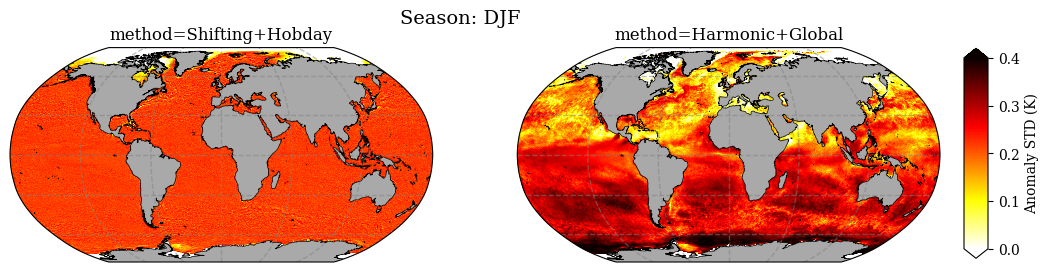

2026-10-10 23:25:43 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:25:49 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.00s


2026-10-10 23:25:49 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:25:55 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.01s


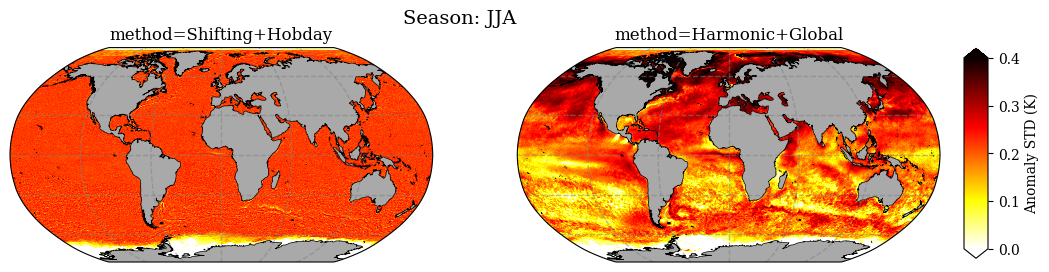

2026-10-10 23:25:59 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:26:04 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 5.96s


2026-10-10 23:26:04 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:26:10 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.01s


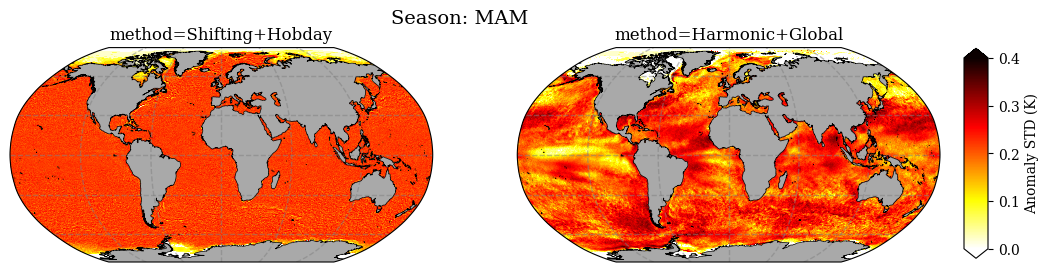

2026-10-10 23:26:14 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:26:20 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.01s


2026-10-10 23:26:20 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:26:26 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.02s


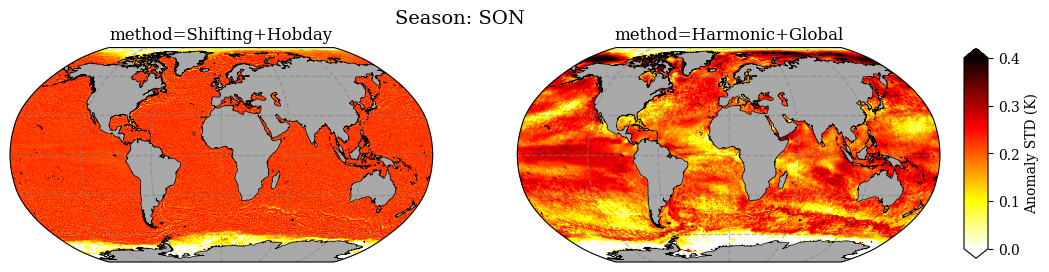

In [13]:
shifting_seasonal_std = extremes_ds_shifting.extreme_events.groupby("time.season").std(dim="time").persist()
detrend_seasonal_std = extremes_ds_detrend.extreme_events.groupby("time.season").std(dim="time").persist()

# Add method coordinate and concatenate
shifting_seasonal_std = shifting_seasonal_std.expand_dims({"method": ["Shifting+Hobday"]})
detrend_seasonal_std = detrend_seasonal_std.expand_dims({"method": ["Harmonic+Global"]})
combined_seasonal_std = xr.concat([shifting_seasonal_std, detrend_seasonal_std], dim="method")

config = marEx.PlotConfig(
    var_units="Anomaly STD (K)",
    cmap="hot_r",
    clim=[0, 0.4],
    grid_labels=False,
    show_colorbar=True,
)

seasons = combined_seasonal_std["season"].values

for season in seasons:
    data = combined_seasonal_std.sel(season=season)
    fig, axes = data.plotX.multi_plot(config, col="method", col_wrap=2)
    fig.suptitle(f"Season: {season}", fontsize=14)
    plt.show()

## Global Extreme Event Frequency

Under the Hobday definition, extremes are by construction relative to the time of year. The seasonal pattern in the
harmonic-detrended frequency therefore comes from the non-harmonic shape of the seasonal cycle (cf. the time series
above).

2026-10-10 23:26:36 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:26:46 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 9.49s


2026-10-10 23:26:46 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:27:01 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 15.37s


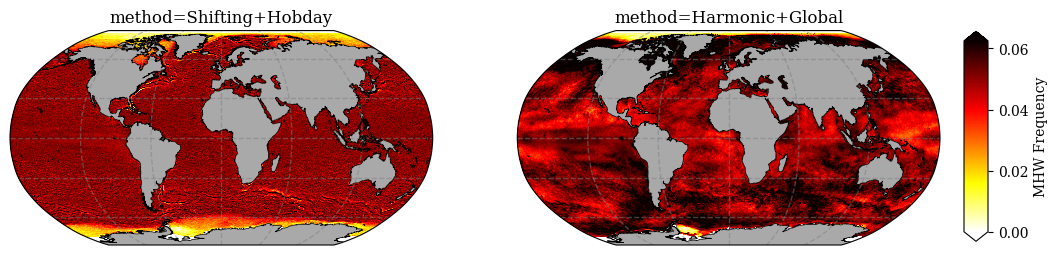

In [14]:
shifting_frequency = extremes_ds_shifting.extreme_events.mean(dim="time")
detrend_frequency = extremes_ds_detrend.extreme_events.mean(dim="time")

config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True)

combined_frequency = xr.concat([shifting_frequency, detrend_frequency], dim="method")
combined_frequency = combined_frequency.assign_coords(method=["Shifting+Hobday", "Harmonic+Global"])

fig, axes = combined_frequency.plotX.multi_plot(config, col="method", col_wrap=2)

2026-10-10 23:27:06 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:27:48 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 42.50s


2026-10-10 23:27:48 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:27:54 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.04s


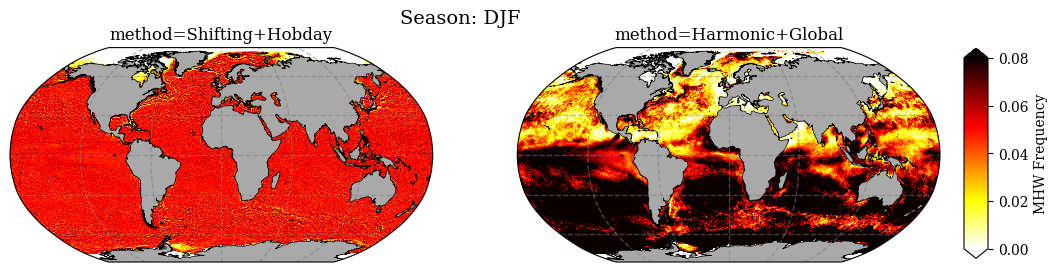

2026-10-10 23:27:57 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:03 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.02s


2026-10-10 23:28:03 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:09 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 6.06s


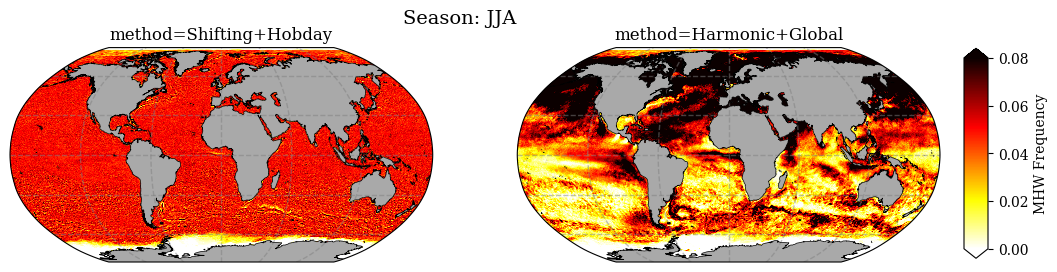

2026-10-10 23:28:13 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:19 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 5.98s


2026-10-10 23:28:19 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:25 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 5.99s


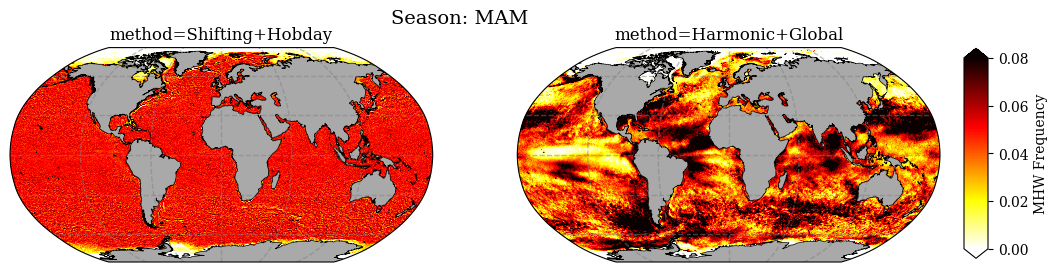

2026-10-10 23:28:28 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:34 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 5.84s


2026-10-10 23:28:34 - marEx.plotX.gridded - INFO - [PID:419237] - Starting Gridded plot rendering


2026-10-10 23:28:39 - marEx.plotX.gridded - INFO - [PID:419237] - Completed Gridded plot rendering in 5.92s


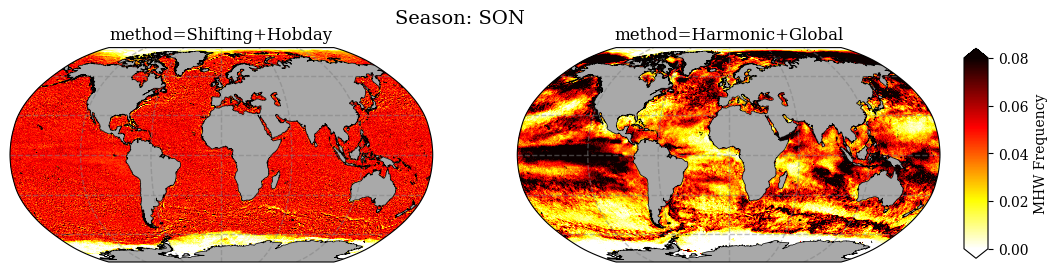

In [15]:
shifting_seasonal_frequency = extremes_ds_shifting.extreme_events.groupby("time.season").mean(dim="time").persist()
detrend_seasonal_frequency = extremes_ds_detrend.extreme_events.groupby("time.season").mean(dim="time").persist()

# Add method coordinate and concatenate
shifting_seasonal_frequency = shifting_seasonal_frequency.expand_dims({"method": ["Shifting+Hobday"]})
detrend_seasonal_frequency = detrend_seasonal_frequency.expand_dims({"method": ["Harmonic+Global"]})
combined_seasonal_frequency = xr.concat([shifting_seasonal_frequency, detrend_seasonal_frequency], dim="method")

config = marEx.PlotConfig(
    var_units="MHW Frequency",
    cmap="hot_r",
    clim=[0, 0.08],
    grid_labels=False,
    show_colorbar=True,
)

seasons = combined_seasonal_frequency["season"].values

for season in seasons:
    data = combined_seasonal_frequency.sel(season=season)
    fig, axes = data.plotX.multi_plot(config, col="method", col_wrap=2)
    fig.suptitle(f"Season: {season}", fontsize=14)
    plt.show()

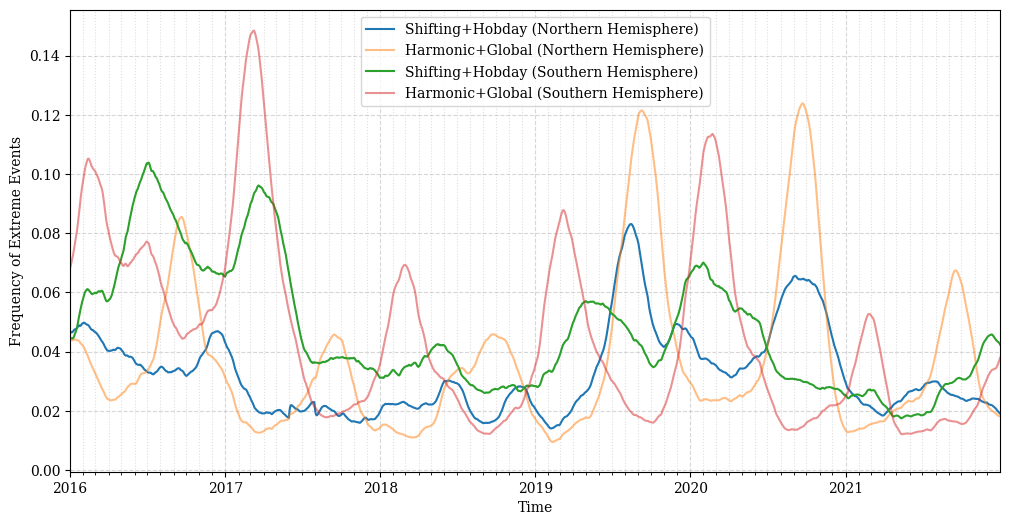

In [16]:
# Northern Hemisphere
monthly_shifting_north = extremes_ds_shifting.extreme_events.sel(lat=slice(0, 90)).mean(dim=["lat", "lon"]).rolling(time=60).mean()
monthly_detrend_north = extremes_ds_detrend.extreme_events.sel(lat=slice(0, 90)).mean(dim=["lat", "lon"]).rolling(time=60).mean()

# Southern Hemisphere
monthly_shifting_south = extremes_ds_shifting.extreme_events.sel(lat=slice(-90, 0)).mean(dim=["lat", "lon"]).rolling(time=60).mean()
monthly_detrend_south = extremes_ds_detrend.extreme_events.sel(lat=slice(-90, 0)).mean(dim=["lat", "lon"]).rolling(time=60).mean()

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_shifting_north.time,
    monthly_shifting_north,
    label="Shifting+Hobday (Northern Hemisphere)",
)
plt.plot(
    monthly_detrend_north.time,
    monthly_detrend_north,
    label="Harmonic+Global (Northern Hemisphere)",
    alpha=0.5,
)
plt.plot(
    monthly_shifting_south.time,
    monthly_shifting_south,
    label="Shifting+Hobday (Southern Hemisphere)",
)
plt.plot(
    monthly_detrend_south.time,
    monthly_detrend_south,
    label="Harmonic+Global (Southern Hemisphere)",
    alpha=0.5,
)
plt.grid(True, which="major", linestyle="--", alpha=0.5)
plt.grid(True, which="minor", linestyle=":", alpha=0.4, axis="x")
plt.xlabel("Time")
plt.ylabel("Frequency of Extreme Events")
plt.xlim(np.datetime64(plot_window.start), np.datetime64(plot_window.stop))
plt.gca().xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(2, 13)))
plt.legend()
plt.show()

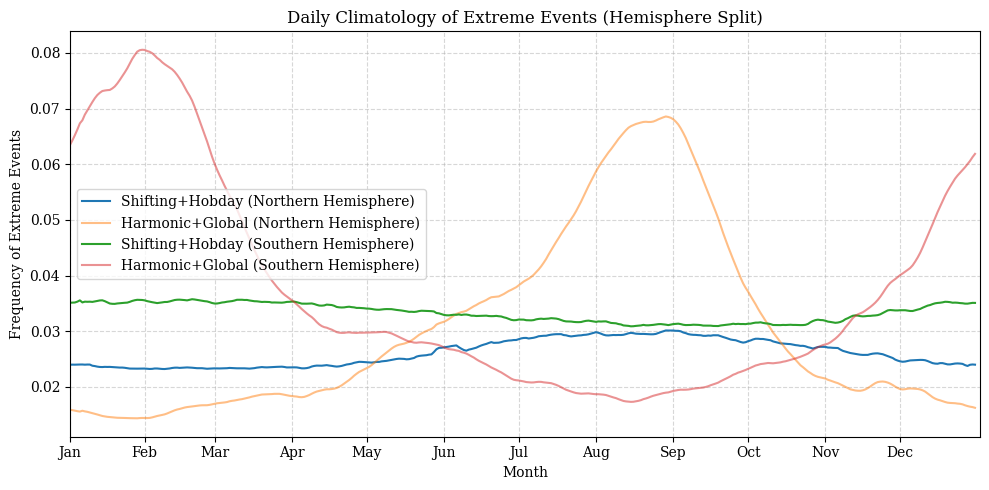

In [17]:
# Daily climatology split by hemisphere
monthly_shifting_north = (
    extremes_ds_shifting.extreme_events.sel(lat=slice(0, 90))
    .mean(dim=["lat", "lon"])
    .rolling(time=10, center=True)
    .mean("time")
    .groupby("time.dayofyear")
    .mean(dim="time")
    .isel(dayofyear=slice(0, -2))
)
monthly_shifting_south = (
    extremes_ds_shifting.extreme_events.sel(lat=slice(-90, 0))
    .mean(dim=["lat", "lon"])
    .rolling(time=10, center=True)
    .mean("time")
    .groupby("time.dayofyear")
    .mean(dim="time")
    .isel(dayofyear=slice(0, -2))
)
monthly_detrend_north = (
    extremes_ds_detrend.extreme_events.sel(lat=slice(0, 90))
    .mean(dim=["lat", "lon"])
    .rolling(time=10, center=True)
    .mean("time")
    .groupby("time.dayofyear")
    .mean(dim="time")
    .isel(dayofyear=slice(0, -2))
)
monthly_detrend_south = (
    extremes_ds_detrend.extreme_events.sel(lat=slice(-90, 0))
    .mean(dim=["lat", "lon"])
    .rolling(time=10, center=True)
    .mean("time")
    .groupby("time.dayofyear")
    .mean(dim="time")
    .isel(dayofyear=slice(0, -2))
)

days = monthly_shifting_north.dayofyear.values
month_starts = [1] + list(np.cumsum([calendar.monthrange(2001, m)[1] for m in range(1, 12)]))
month_labels = [calendar.month_abbr[m] for m in range(1, 13)]

plt.figure(figsize=(10, 5))
plt.plot(days, monthly_shifting_north, label="Shifting+Hobday (Northern Hemisphere)")
plt.plot(days, monthly_detrend_north, label="Harmonic+Global (Northern Hemisphere)", alpha=0.5)
plt.plot(days, monthly_shifting_south, label="Shifting+Hobday (Southern Hemisphere)")
plt.plot(days, monthly_detrend_south, label="Harmonic+Global (Southern Hemisphere)", alpha=0.5)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlabel("Month")
plt.ylabel("Frequency of Extreme Events")
plt.title("Daily Climatology of Extreme Events (Hemisphere Split)")
plt.legend()

plt.xticks(month_starts, month_labels)
plt.xlim(1, 366)
plt.tight_layout()
plt.show()

## Wall Time and Memory

One row per stage, measured while the notebook ran on the cluster configured at the top. Peak worker memory is the
summed process memory the workers report to the scheduler, which is the quantity Dask compares against `memory_limit`.
The client (this kernel) is counted separately.

In [18]:
monitor.summary()

,wall (min),peak worker memory (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,
Detect: shifting baseline + Hobday,75.16,52.98,3.05,73.01,0
Detect: harmonic detrend + global threshold,23.22,54.53,3.16,65.09,0
total,98.38,54.53,3.16,73.01,0


In [19]:
client.close()